In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_trips

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

trips = load_trips()
train = trips[trips["split"] == "train"]
valid = trips[trips["split"] == "valid"]

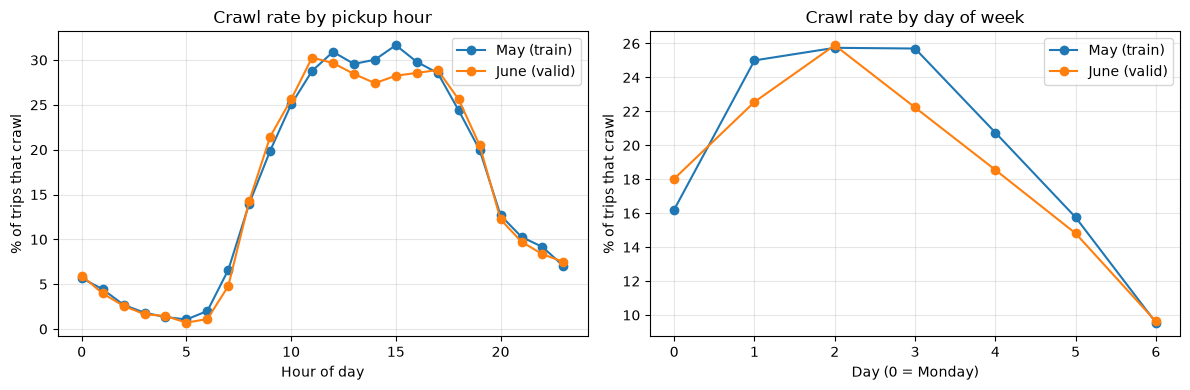

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for df, label in [(train, "May (train)"), (valid, "June (valid)")]:
    pickup = df["tpep_pickup_datetime"]
    df.groupby(pickup.dt.hour)["is_crawl"].mean().mul(100).plot(ax=axes[0], marker="o", label=label)
    df.groupby(pickup.dt.day_of_week)["is_crawl"].mean().mul(100).plot(ax=axes[1], marker="o", label=label)

axes[0].set(title="Crawl rate by pickup hour", xlabel="Hour of day", ylabel="% of trips that crawl")
axes[1].set(title="Crawl rate by day of week", xlabel="Day (0 = Monday)", ylabel="% of trips that crawl")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "crawl_rate_hour_weekday.png", dpi=150)
plt.show()